In [1]:
# Cell 1
import os
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

# Torchvision 3D models
import torchvision
from torchvision.models.video import r3d_18


In [2]:
# Cell 2
dataset_dir = "../preprocessed/dataset_splits"  # Same dataset as before

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


Using device: cpu


In [3]:
# Cell 3
class LungNoduleDataset(torch.utils.data.Dataset):
    def __init__(self, split):
        self.folder = os.path.join(dataset_dir, split)
        self.files = [os.path.join(self.folder, f) for f in os.listdir(self.folder) if f.endswith(".npz")]

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        data = np.load(self.files[idx])
        patch = data['patch']
        label = data['label']

        patch = torch.tensor(patch, dtype=torch.float32).unsqueeze(0)  # (1, 64, 64, 64)
        label = torch.tensor(label, dtype=torch.long)
        return patch, label


In [13]:
# Cell 4
batch_size = 16

train_dataset = LungNoduleDataset(split="train")
val_dataset = LungNoduleDataset(split="val")
test_dataset = LungNoduleDataset(split="test")

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)


In [14]:
from torchvision.models.video import r3d_18
import torch.nn as nn

# Load model
model = r3d_18(weights=None)

# ✅ Change the first conv layer to accept 1 channel instead of 3
model.stem[0] = nn.Conv3d(1, 64, kernel_size=(3,7,7), stride=(1,2,2), padding=(1,3,3), bias=False)

# ✅ Change the final FC layer to output 2 classes
model.fc = nn.Linear(model.fc.in_features, 2)

# Move to device
model = model.to(device)


In [15]:
# Cell 6
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-4)


In [16]:
# Cell 7
num_epochs = 20
best_val_loss = float("inf")

train_losses = []
val_losses = []
val_accuracies = []


In [17]:
# Cell 8
for epoch in range(num_epochs):
    model.train()
    train_loss = 0.0

    for patches, labels in train_loader:
        patches, labels = patches.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(patches)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    model.eval()
    val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for patches, labels in val_loader:
            patches, labels = patches.to(device), labels.to(device)
            outputs = model(patches)
            loss = criterion(outputs, labels)
            val_loss += loss.item()

            preds = outputs.argmax(dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    avg_train_loss = train_loss / len(train_loader)
    avg_val_loss = val_loss / len(val_loader)
    val_acc = correct / total

    train_losses.append(avg_train_loss)
    val_losses.append(avg_ &val_loss)
    val_accuracies.append(val_acc)

    print(f"Epoch [{epoch+1}/{num_epochs}], Train Loss: {avg_train_loss:.4f}, Val Loss: {avg_val_loss:.4f}, Val Acc: {val_acc:.4f}")

    # Save best model
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        torch.save(model.state_dict(), "best_model_resnet18.pth")
        print("✅ Best model saved.")


Epoch [1/20], Train Loss: 0.5515, Val Loss: 0.6107, Val Acc: 0.7241
✅ Best model saved.
Epoch [2/20], Train Loss: 0.4033, Val Loss: 0.5163, Val Acc: 0.7931
✅ Best model saved.
Epoch [3/20], Train Loss: 0.2381, Val Loss: 0.4874, Val Acc: 0.7241
✅ Best model saved.
Epoch [4/20], Train Loss: 0.1398, Val Loss: 1.0305, Val Acc: 0.3448
Epoch [5/20], Train Loss: 0.0696, Val Loss: 0.4785, Val Acc: 0.8276
✅ Best model saved.
Epoch [6/20], Train Loss: 0.0482, Val Loss: 0.6015, Val Acc: 0.8276
Epoch [7/20], Train Loss: 0.0499, Val Loss: 0.2369, Val Acc: 0.8966
✅ Best model saved.
Epoch [8/20], Train Loss: 0.0246, Val Loss: 0.2817, Val Acc: 0.8621
Epoch [9/20], Train Loss: 0.0291, Val Loss: 1.8870, Val Acc: 0.5517
Epoch [10/20], Train Loss: 0.0537, Val Loss: 0.1159, Val Acc: 0.9310
✅ Best model saved.
Epoch [11/20], Train Loss: 0.0896, Val Loss: 6.0629, Val Acc: 0.2414
Epoch [12/20], Train Loss: 0.1294, Val Loss: 0.1739, Val Acc: 0.9310
Epoch [13/20], Train Loss: 0.1290, Val Loss: 1.5370, Val Acc:

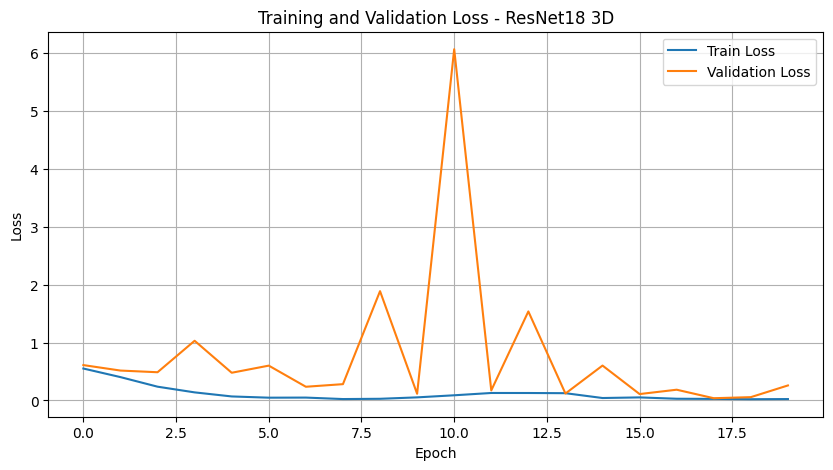

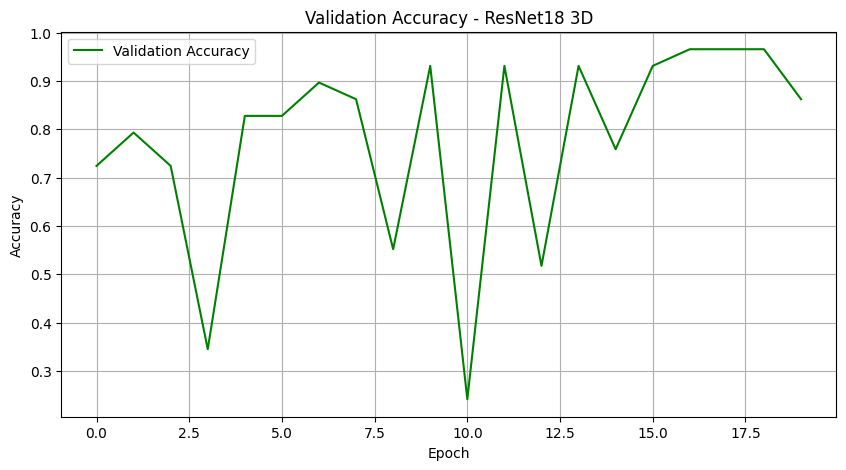

In [18]:
# Cell 9
plt.figure(figsize=(10,5))
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")
plt.title("Training and Validation Loss - ResNet18 3D")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(10,5))
plt.plot(val_accuracies, label="Validation Accuracy", color='green')
plt.title("Validation Accuracy - ResNet18 3D")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()


In [9]:
# Cell 1
from torchcam.methods import SmoothGradCAMpp


In [19]:
# Cell 2
model = r3d_18(weights=None)

# Fix 1-channel input
model.stem[0] = nn.Conv3d(1, 64, kernel_size=(3,7,7), stride=(1,2,2), padding=(1,3,3), bias=False)

# Fix 2-class output
model.fc = nn.Linear(model.fc.in_features, 2)

# Move to device
model = model.to(device)

# Load trained weights
model.load_state_dict(torch.load("best_model_resnet18.pth"))
model.eval()


VideoResNet(
  (stem): BasicStem(
    (0): Conv3d(1, 64, kernel_size=(3, 7, 7), stride=(1, 2, 2), padding=(1, 3, 3), bias=False)
    (1): BatchNorm3d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Sequential(
        (0): Conv3DSimple(64, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias=False)
        (1): BatchNorm3d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
      (conv2): Sequential(
        (0): Conv3DSimple(64, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias=False)
        (1): BatchNorm3d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (relu): ReLU(inplace=True)
    )
    (1): BasicBlock(
      (conv1): Sequential(
        (0): Conv3DSimple(64, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1), bias=False)
        (1):

In [21]:
# Cell 3 (corrected)

# Tell TorchCAM manually the layer name for activation maps
cam_extractor = SmoothGradCAMpp(model, target_layer="layer4.1.conv2")


In [22]:
# Pick one sample
sample_patch, sample_label = test_dataset[0]

# Prepare for model
sample_patch = sample_patch.unsqueeze(0).to(device)

# Forward pass
output = model(sample_patch)
pred_label = output.argmax(dim=1)

# Get the first CAM
cam = cam_extractor(pred_label.item(), output)[0]


In [23]:
import torch.nn.functional as F

# Correct unsqueeze
print("cam shape:", cam.shape)  # should be [1, 8, 4, 4]

cam_tensor = cam.unsqueeze(0).to(device)  # (1,1,8,4,4)

print("cam_tensor shape after unsqueeze:", cam_tensor.shape)  # should be (1,1,8,4,4)

# Now correctly interpolate
cam_resized_tensor = F.interpolate(
    cam_tensor,
    size=(64, 64, 64),
    mode='trilinear',
    align_corners=False
)

cam_resized = cam_resized_tensor.squeeze().cpu().numpy()

# Normalize
cam_resized = (cam_resized - np.min(cam_resized)) / (np.max(cam_resized) - np.min(cam_resized))


cam shape: torch.Size([1, 8, 4, 4])
cam_tensor shape after unsqueeze: torch.Size([1, 1, 8, 4, 4])


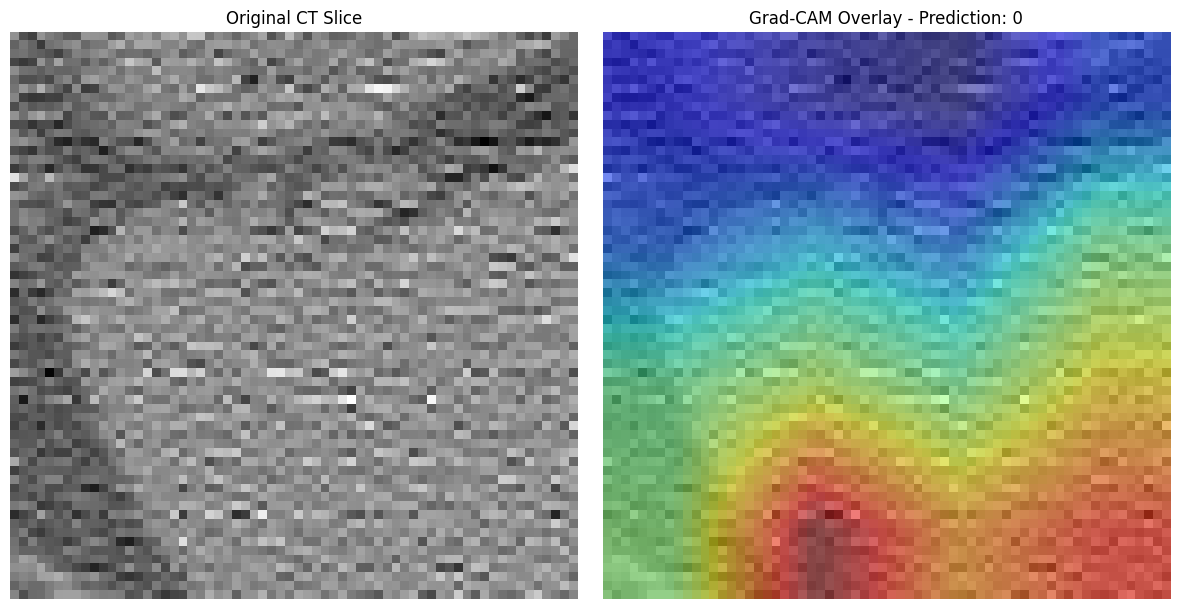

In [25]:
import matplotlib.pyplot as plt

# Convert patch to numpy (in case you haven't)
patch_np = sample_patch.squeeze().cpu().numpy()

# Pick middle slice
mid_slice_idx = patch_np.shape[0] // 2

plt.figure(figsize=(12,6))

# Original CT Slice
plt.subplot(1,2,1)
plt.imshow(patch_np[mid_slice_idx, :, :], cmap='gray')
plt.title("Original CT Slice")
plt.axis('off')

# CT + Grad-CAM overlay
plt.subplot(1,2,2)
plt.imshow(patch_np[mid_slice_idx, :, :], cmap='gray')
plt.imshow(cam_resized[mid_slice_idx, :, :], cmap='jet', alpha=0.5)
plt.title(f"Grad-CAM Overlay - Prediction: {pred_label.item()}")
plt.axis('off')

plt.tight_layout()
plt.show()


RuntimeError: cannot register a hook on a tensor that doesn't require gradient